# What happens when a virtual Icechunk cube goes stale?

Landsat and HLS republish and delete scenes. If those COGs are virtualized into an
Icechunk cube, what does an Xarray read do once the cube is out of date?

Setup: `docker compose up -d` (moto S3 on localhost:5000), then run this notebook.

The matrix:

| axis | values |
|---|---|
| checksum written into refs | `lastmod` (VirtualiZarr default), `etag` |
| change to the archive | `overwrite` scene t=40 (republish, +5000), `delete` scene t=70 |
| read mode | `strict`, `tolerant`, `ignore-checksum`, `check-then-repair` |


In [1]:
import logging
import time

import icechunk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from stale_cube import config, data, readers
from stale_cube.report import EXPECTED, T_DELETE, T_OVERWRITE, changed_step, outcome
from stale_cube.virtualize import build_cube, open_repo

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")


## 1. Build the archive and four independent cubes

100 monthly COGs (1024x1024, 256x256 deflate tiles) per scenario, each virtualized into its own Icechunk repo.

In [2]:
config.reset_bucket()

SCENARIOS = [(c, ch) for c in ("lastmod", "etag") for ch in ("overwrite", "delete")]

def prefix(checksum, change):
    return f"{checksum}-{change}"

t0 = time.perf_counter()
for checksum, change in SCENARIOS:
    p = prefix(checksum, change)
    build_cube(p, data.write_archive(p), checksum)
print(f"built {len(SCENARIOS)} cubes in {time.perf_counter() - t0:.1f}s")


built 4 cubes in 22.3s


## 2. Fresh cube: one pixel, 100 observations

Plain Icechunk + Xarray: open the repo, take a read-only session, open its store with Xarray.

In [3]:
repo = open_repo(prefix("etag", "overwrite"))
session = repo.readonly_session("main")
ds = xr.open_zarr(session.store, consolidated=False)
ds


<xarray.Dataset> Size: 419MB
Dimensions:  (time: 100, y: 1024, x: 1024)
Coordinates:
  * time     (time) datetime64[ns] 800B 2017-01-01 2017-02-01 ... 2025-04-01
Dimensions without coordinates: y, x
Data variables:
    band     (time, y, x) float32 419MB dask.array<chunksize=(1, 256, 256), meta=np.ndarray>
Attributes:
    source_etags:  {'s3://stale-cube/etag-overwrite/cogs/scene_202209.tif': '...

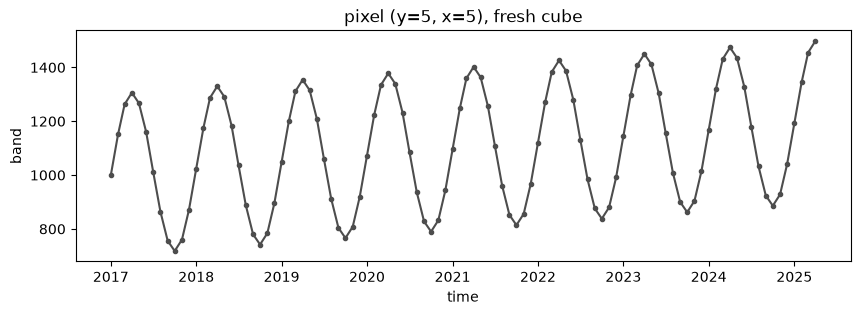

In [4]:
pixel = ds["band"].isel(y=5, x=5).compute()
assert np.array_equal(pixel.values, EXPECTED)
pixel.plot(marker=".", color="0.3", figsize=(10, 3))
plt.title("pixel (y=5, x=5), fresh cube"); plt.show()


## 3. The archive changes underneath the cube

Republish scene t=40 (values +5000, new bytes, new ETag) or delete scene t=70. The cubes are not touched.

In [5]:
for checksum, change in SCENARIOS:
    p = prefix(checksum, change)
    if change == "overwrite":
        data.republish(p, T_OVERWRITE)
    else:
        data.delete(p, T_DELETE)
print(f"republished {data.TIMES[T_OVERWRITE]:%Y-%m}, deleted {data.TIMES[T_DELETE]:%Y-%m}")


republished 2020-05, deleted 2022-11


## 4. Strict read: does the whole time series blow up?

The exact same read as above, on a new session after scene t=40 was republished:

In [6]:
ds = xr.open_zarr(repo.readonly_session("main").store, consolidated=False)
try:
    ds["band"].isel(y=5, x=5).compute()
except icechunk.IcechunkError as exc:
    print(f"{type(exc).__name__} kind={exc.kind}")
    print(str(exc).splitlines()[0])


StorageError kind=virtual-chunk-modified
the checksum of the object owning the virtual chunk has changed (s3://stale-cube/etag-overwrite/cogs/scene_202005.tif)


Yes: **one** stale scene out of 100 fails the entire pixel read. Reading any
other time step on its own still works:

In [7]:
print("t=39:", ds["band"].isel(y=5, x=5, time=T_OVERWRITE - 1).values)
try:
    ds["band"].isel(y=5, x=5, time=T_OVERWRITE).values
except icechunk.IcechunkError as exc:
    print(f"t={T_OVERWRITE}: {exc.kind}")


t=39: 1378.0
t=40: virtual-chunk-modified


Same read across all four cubes. `readers.read_strict` is the code above with
the exception captured, so the matrix can be tabulated.

In [8]:
results = {}
for checksum, change in SCENARIOS:
    res = readers.read_strict(open_repo(prefix(checksum, change)))
    results[(checksum, change, "strict")] = res
    print(f"{checksum:>7} x {change:<9} -> {outcome(res, change)}")
    if res.error:
        print(f"{'':20}{res.error[:150]}")


lastmod x overwrite -> RAISES (virtual-chunk-modified)
                    StorageError: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/lastmod-overwrite/cogs/scene_202005.tif)


lastmod x delete    -> RAISES (virtual-chunk-fetch)
                    StorageError: error fetching virtual reference: service error: NoSuchKey: 
   etag x overwrite -> RAISES (virtual-chunk-modified)
                    StorageError: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/etag-overwrite/cogs/scene_202005.tif)


   etag x delete    -> RAISES (virtual-chunk-fetch)
                    StorageError: error fetching virtual reference: service error: NoSuchKey: 


## 5. Tolerant read: keep working with missing observations

`readers.TolerantStore` wraps the Icechunk store. Chunks that fail with
`virtual-chunk-modified`, or `virtual-chunk-fetch` + NoSuchKey, are returned as
missing, so zarr fills them with the fill value (decoded to NaN). Every skip is
logged and recorded. Any other error still raises.

The only change from the strict read is wrapping the store:

WARNING stale_cube.readers: skipping modified chunk band/c/40/0/0: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/etag-overwrite/cogs/scene_202005.tif)


skipped time steps: {40: 'modified'}


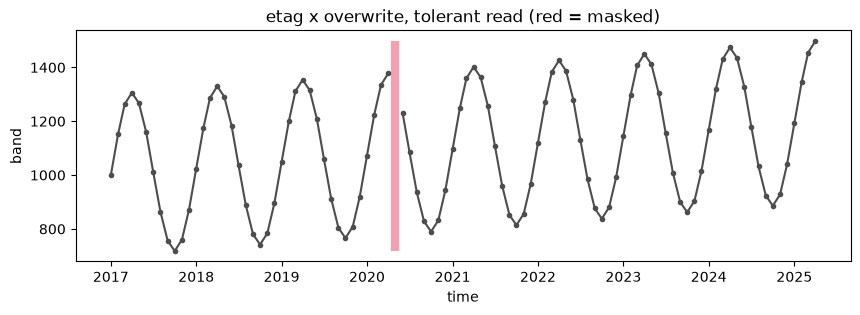

In [9]:
store = readers.TolerantStore(repo.readonly_session("main").store)
ds = xr.open_zarr(store, consolidated=False)
pixel = ds["band"].isel(y=5, x=5).compute()

print("skipped time steps:", store.skipped_times())
mask = pixel.time.isin(pixel.time[list(store.skipped_times())])
pixel.plot(marker=".", color="0.3", figsize=(10, 3))
plt.vlines(pixel.time[mask], pixel.min(), pixel.max(), color="crimson", alpha=0.4, lw=6)
plt.title("etag x overwrite, tolerant read (red = masked)"); plt.show()


Same for a production-shaped read: a 512x512 window, all 100 steps, through dask.

In [10]:
store = readers.TolerantStore(repo.readonly_session("main").store)
window = xr.open_zarr(store, consolidated=False, chunks={})["band"].isel(
    y=slice(0, 512), x=slice(0, 512)
)
print(window.data)
window = window.compute()
print("all-NaN time steps:", np.where(window.isnull().all(["y", "x"]))[0])
print("skipped:", store.skipped_times())


dask.array<getitem, shape=(100, 512, 512), dtype=float32, chunksize=(1, 256, 256), chunktype=numpy.ndarray>


WARNING stale_cube.readers: skipping modified chunk band/c/40/1/1: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/etag-overwrite/cogs/scene_202005.tif)


WARNING stale_cube.readers: skipping modified chunk band/c/40/1/0: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/etag-overwrite/cogs/scene_202005.tif)


WARNING stale_cube.readers: skipping modified chunk band/c/40/0/1: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/etag-overwrite/cogs/scene_202005.tif)


WARNING stale_cube.readers: skipping modified chunk band/c/40/0/0: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/etag-overwrite/cogs/scene_202005.tif)


all-NaN time steps: [40]
skipped: {40: 'modified'}


All four cubes (`readers.read_tolerant` = the wrapped-store read above):

In [11]:
for checksum, change in SCENARIOS:
    res = readers.read_tolerant(open_repo(prefix(checksum, change)))
    results[(checksum, change, "tolerant")] = res
    print(f"{checksum:>7} x {change:<9} -> {outcome(res, change)}   skipped={res.skipped}")


WARNING stale_cube.readers: skipping modified chunk band/c/40/0/0: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/lastmod-overwrite/cogs/scene_202005.tif)


WARNING stale_cube.readers: skipping missing chunk band/c/70/0/0: error fetching virtual reference: service error: NoSuchKey: 


lastmod x overwrite -> 99/99 others ok, t=40: NaN (flagged in mask)   skipped={40: 'modified'}


WARNING stale_cube.readers: skipping modified chunk band/c/40/0/0: the checksum of the object owning the virtual chunk has changed (s3://stale-cube/etag-overwrite/cogs/scene_202005.tif)


lastmod x delete    -> 99/99 others ok, t=70: NaN (flagged in mask)   skipped={70: 'missing'}


WARNING stale_cube.readers: skipping missing chunk band/c/70/0/0: error fetching virtual reference: service error: NoSuchKey: 


   etag x overwrite -> 99/99 others ok, t=40: NaN (flagged in mask)   skipped={40: 'modified'}


   etag x delete    -> 99/99 others ok, t=70: NaN (flagged in mask)   skipped={70: 'missing'}


### The tolerant reader is also your change feed

With ETags, the skipped keys tell you which source files changed. You learn that
from reads you are already doing, without waiting for the provider to announce
anything. Without ETags, a republished scene raises nothing, see below.

## 6. There is no checksum-free cube by default

`virtualizarr`'s `to_icechunk` always writes a last-modified checksum: when
`last_updated_at` is None it uses `now() + 1s`. So even the `lastmod` cubes
refuse stale chunks. A cube with no checksums at all (stripped refs, or written
by other tooling) is what the `ignore-checksum` mode below reads.

## 7. `ignore-checksum`: what a reader-side "read it anyway" would return

Refs are rewritten without checksums in an uncommitted session, then discarded.

In [12]:
for checksum, change in SCENARIOS:
    res = readers.read_ignore_checksum(open_repo(prefix(checksum, change)))
    results[(checksum, change, "ignore-checksum")] = res
    print(f"{checksum:>7} x {change:<9} -> {outcome(res, change)}")


lastmod x overwrite -> RAISES (error: Error -5 while decompressing data: incomplete or truncated stream)


lastmod x delete    -> RAISES (virtual-chunk-fetch)


   etag x overwrite -> RAISES (error: Error -5 while decompressing data: incomplete or truncated stream)


   etag x delete    -> RAISES (virtual-chunk-fetch)


Old offsets and lengths point into a file whose tiles have moved and resized.
Tile (0, 0) starts at the same offset in both files, so whether the pixel read
fails depends on whether that tile grew (truncated stream) or shrank (decodes by
luck, zlib ignores trailing bytes). Reading the whole republished scene hits the
shifted tiles:

In [13]:
res = readers.read_ignore_checksum(open_repo(prefix("etag", "overwrite")), sel=dict(time=T_OVERWRITE))
print(res.error or "decoded without error (values are not trustworthy)")


error: Error -3 while decompressing data: incorrect header check


## 8. Check-then-repair: the background maintenance job

HEAD every source file and compare to the ETags the writer recorded in group
attributes. Then commit one repair: re-virtualize changed scenes, drop refs for
deleted ones. Readers keep running against the old snapshot until then.

In [14]:
repair_rows = {}
for checksum, change in SCENARIOS:
    p = prefix(checksum, change)
    repo = open_repo(p)
    t0 = time.perf_counter()
    stale = readers.check(repo, p)
    dt = time.perf_counter() - t0
    readers.repair(repo, p, stale)
    after = readers.read_strict(open_repo(p))
    after.mode = "check-then-repair"
    results[(checksum, change, "check-then-repair")] = after
    repair_rows[(checksum, change)] = (stale, dt)
    print(f"{checksum:>7} x {change:<9} -> found {stale or 'nothing'} in {dt:.2f}s "
          f"({data.N_TIMES} HEADs); after repair: {outcome(after, change)}")


lastmod x overwrite -> found nothing in 0.35s (100 HEADs); after repair: RAISES (virtual-chunk-modified)


lastmod x delete    -> found {70: 'missing'} in 0.43s (100 HEADs); after repair: 99/99 others ok, t=70: NaN (ref removed by repair)


   etag x overwrite -> found {40: 'modified'} in 0.43s (100 HEADs); after repair: 99/99 others ok, t=40: republished value


   etag x delete    -> found {70: 'missing'} in 0.34s (100 HEADs); after repair: 99/99 others ok, t=70: NaN (ref removed by repair)


Re-read the repaired cube with plain Xarray:

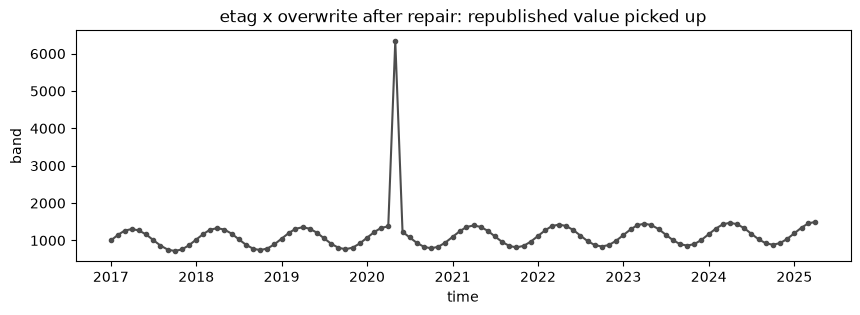

In [15]:
ds = xr.open_zarr(open_repo(prefix("etag", "overwrite")).readonly_session("main").store,
                  consolidated=False)
pixel = ds["band"].isel(y=5, x=5).compute()
pixel.plot(marker=".", color="0.3", figsize=(10, 3))
plt.title("etag x overwrite after repair: republished value picked up"); plt.show()


## 9. Summary

In [16]:
MODES = ["strict", "tolerant", "ignore-checksum", "check-then-repair"]
rows = []
for checksum, change in SCENARIOS:
    for mode in MODES:
        res = results[(checksum, change, mode)]
        note = ""
        if mode == "check-then-repair":
            stale, _ = repair_rows[(checksum, change)]
            note = f"check found {stale or 'nothing'}; then "
        rows.append(dict(checksum=checksum, change=change, mode=mode,
                         outcome=note + outcome(res, change)))
summary = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", None):
    display(summary)


,checksum,change,mode,outcome
0,lastmod,overwrite,strict,RAISES (virtual-chunk-modified)
1,lastmod,overwrite,tolerant,"99/99 others ok, t=40: NaN (flagged in mask)"
2,lastmod,overwrite,ignore-checksum,RAISES (error: Error -5 while decompressing data: incomplete or truncated stream)
3,lastmod,overwrite,check-then-repair,check found nothing; then RAISES (virtual-chunk-modified)
4,lastmod,delete,strict,RAISES (virtual-chunk-fetch)
5,lastmod,delete,tolerant,"99/99 others ok, t=70: NaN (flagged in mask)"
6,lastmod,delete,ignore-checksum,RAISES (virtual-chunk-fetch)
7,lastmod,delete,check-then-repair,"check found {70: 'missing'}; then 99/99 others ok, t=70: NaN (ref removed by repair)"
8,etag,overwrite,strict,RAISES (virtual-chunk-modified)
9,etag,overwrite,tolerant,"99/99 others ok, t=40: NaN (flagged in mask)"
